# R04 · Dropout-rate sweeps (M2b LSTM, M5 Dense-Dropout), 3 seeds each

* **M2b:** LSTM+MCD with p ∈ {0.001, 0.005, 0.01, 0.02, 0.05}, using the M2 learning rate / latent size from R02.
* **M5:** single-dropout dense model, p ∈ {0.05, 0.1, 0.2, 0.3, 0.5}, dropout OFF (DET) and MCD inference.

Same metrics as R03. Each point is the mean over 3 seeds; the band shows the spread.

In [1]:
# ── Settings ──────────────────────────────────────────────────────────────
import os
WORKERS = int(os.environ.get("REV_WORKERS", 8))   # training jobs side by side on the GPU
DEVICE  = None     # None = use the GPU if there is one
RESULTS = os.environ.get("REV_RESULTS", "results")
RUN     = os.environ.get("REV_RUN", "1") == "1"   # False = skip training, rebuild tables/figures from results/

import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import report, plots
from scripts.run_jobs import run_stage, stage_tags
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
os.makedirs("tables_rev", exist_ok=True)

def export(df, name):
    """Save a table as tables_rev/REV_<name>.csv and show it."""
    path = f"tables_rev/REV_{name}.csv"; df.to_csv(path); display(df); print("saved", path)

In [2]:
if RUN:
    failed = run_stage("sweeps", workers=WORKERS, device=DEVICE, results=RESULTS)

In [3]:
df = report.load(RESULTS)
V = report.views(df)
print(len(df), "records")

250 records


auc_pr std/label_auroc std/error_auroc margin/error_auroc       std/aurc    margin/aurc  n_seeds
dataset p                                                                                                             
NAB     0.001  0.225 ± 0.000   0.604 ± 0.008   0.675 ± 0.006      0.657 ± 0.010  0.099 ± 0.004  0.103 ± 0.001        3
        0.005  0.224 ± 0.002   0.613 ± 0.009   0.692 ± 0.006      0.659 ± 0.015  0.094 ± 0.003  0.104 ± 0.000        3
        0.010  0.227 ± 0.001   0.616 ± 0.014   0.681 ± 0.013      0.642 ± 0.003  0.092 ± 0.005  0.106 ± 0.001        3
        0.020  0.225 ± 0.002   0.622 ± 0.011   0.690 ± 0.008      0.646 ± 0.006  0.090 ± 0.002  0.106 ± 0.002        3
        0.050  0.223 ± 0.002   0.621 ± 0.015   0.696 ± 0.002      0.650 ± 0.011  0.091 ± 0.003  0.106 ± 0.001        3
SKAB    0.001  0.851 ± 0.003   0.727 ± 0.021   0.455 ± 0.024      0.641 ± 0.007  0.256 ± 0.008  0.157 ± 0.004        3
        0.005  0.852 ± 0.003   0.756 ± 0.008   0.454 ± 0.014      0.639 ± 0.005  0.250 ± 0.007  0.156 ± 0.003        3
        0.010  0.852 ± 0.002   0.766 ± 0.014   0.436 ± 0.012      0.639 ± 0.004  0.261 ± 0.012  0.157 ± 0.003        3
        0.020  0.851 ± 0.003   0.764 ± 0.013   0.440 ± 0.025      0.645 ± 0.009  0.261 ± 0.011  0.157 ± 0.003        3
        0.050  0.850 ± 0.001   0.754 ± 0.023   0.440 ± 0.010      0.638 ± 0.003  0.264 ± 0.004  0.158 ± 0.001        3

saved tables_rev/REV_tableE_M2b_sweep.csv


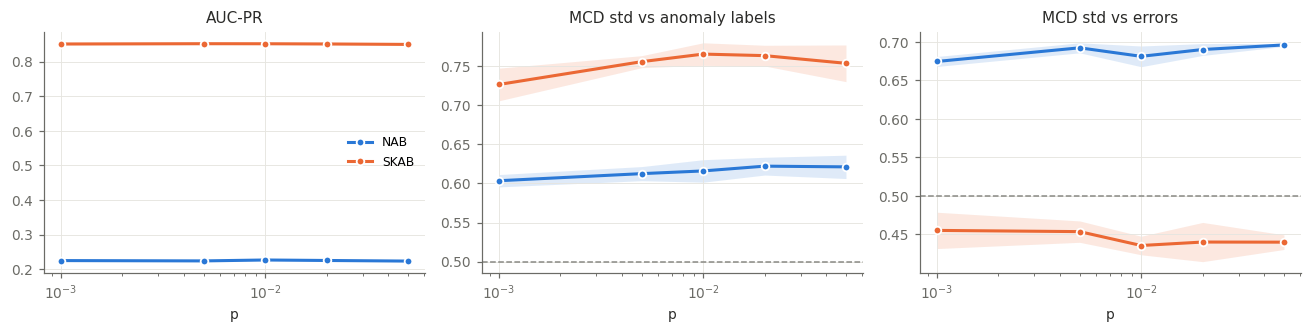

saved figures_rev/REV_M2b_dropout_sweep.png


In [4]:
V = V[V.tag.isin(stage_tags("sweeps"))]        # only the runs of this stage
lstm = V[V.method == "M2 LSTM+MCD"]
cols = ["auc_pr","std/label_auroc","std/error_auroc","margin/error_auroc","std/aurc","margin/aurc"]
export(report.mean_std(lstm, cols, by=("dataset","p")), "tableE_M2b_sweep")
fig, path = plots.sweep_lines(lstm, "p", ["auc_pr","std/label_auroc","std/error_auroc"],
                              ["AUC-PR","MCD std vs anomaly labels","MCD std vs errors"],
                              "REV_M2b_dropout_sweep", logx=True, ref=0.5)
plt.show(); print("saved", path)

auc_pr std/label_auroc std/error_auroc margin/error_auroc       std/aurc    margin/aurc  n_seeds     DET auc_pr
dataset p                                                                                                                           
NAB     0.05  0.219 ± 0.000   0.634 ± 0.002   0.763 ± 0.002      0.620 ± 0.003  0.087 ± 0.000  0.168 ± 0.003        3  0.211 ± 0.000
        0.10  0.223 ± 0.001   0.631 ± 0.008   0.756 ± 0.008      0.620 ± 0.005  0.087 ± 0.001  0.157 ± 0.001        3  0.216 ± 0.001
        0.20  0.231 ± 0.002   0.629 ± 0.008   0.740 ± 0.006      0.611 ± 0.001  0.087 ± 0.002  0.150 ± 0.001        3  0.222 ± 0.001
        0.30  0.235 ± 0.000   0.614 ± 0.001   0.722 ± 0.002      0.620 ± 0.002  0.103 ± 0.001  0.144 ± 0.001        3  0.225 ± 0.000
        0.50  0.231 ± 0.001   0.624 ± 0.007   0.721 ± 0.004      0.636 ± 0.003  0.096 ± 0.006  0.129 ± 0.000        3  0.224 ± 0.001
SKAB    0.05  0.856 ± 0.002   0.762 ± 0.003   0.414 ± 0.002      0.667 ± 0.002  0.276 ± 0.003  0.148 ± 0.002        3  0.856 ± 0.002
        0.10  0.856 ± 0.002   0.767 ± 0.007   0.419 ± 0.004      0.661 ± 0.003  0.270 ± 0.004  0.148 ± 0.003        3  0.856 ± 0.002
        0.20  0.856 ± 0.002   0.770 ± 0.006   0.422 ± 0.007      0.653 ± 0.005  0.265 ± 0.006  0.149 ± 0.002        3  0.855 ± 0.002
        0.30  0.856 ± 0.002   0.774 ± 0.009   0.422 ± 0.008      0.649 ± 0.008  0.262 ± 0.005  0.150 ± 0.002        3  0.855 ± 0.002
        0.50  0.855 ± 0.001   0.782 ± 0.008   0.414 ± 0.005      0.651 ± 0.004  0.270 ± 0.003  0.153 ± 0.001        3  0.854 ± 0.001

saved tables_rev/REV_tableF_M5_sweep.csv


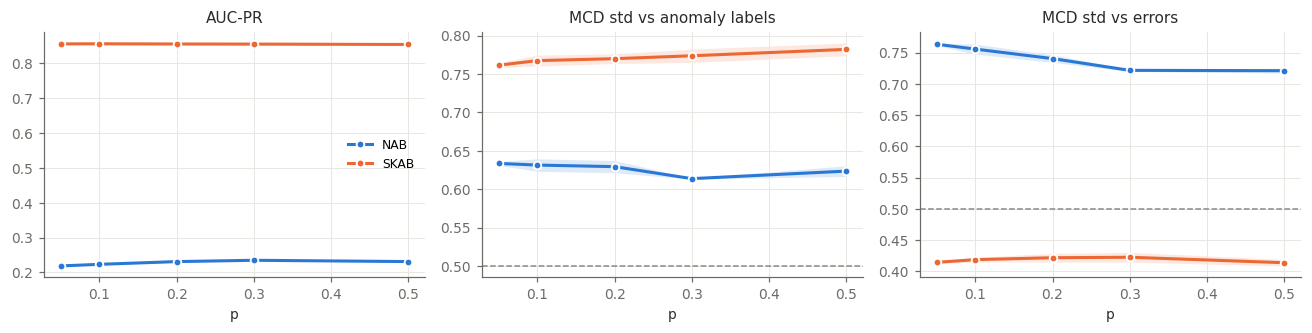

saved figures_rev/REV_M5_dropout_sweep.png


In [5]:
m5 = V[V.method == "M5 DenseDropout"]
m5d = V[V.method == "M5 DenseDropout (DET)"]
t = report.mean_std(m5, cols, by=("dataset","p"))
t["DET auc_pr"] = report.mean_std(m5d, ["auc_pr"], by=("dataset","p"))["auc_pr"]
export(t, "tableF_M5_sweep")
fig, path = plots.sweep_lines(m5, "p", ["auc_pr","std/label_auroc","std/error_auroc"],
                              ["AUC-PR","MCD std vs anomaly labels","MCD std vs errors"],
                              "REV_M5_dropout_sweep", ref=0.5)
plt.show(); print("saved", path)